# 04 · Heart-rate variability from RR intervals

The Polar H10 sends the interval between consecutive heartbeats (RR, in ms, from its ECG) with every heart-rate notification. This notebook turns them into the standard HRV metrics and compares them with the PP intervals of the optical arm sensor.

1. beat times and cleaning
2. time domain, Poincaré and frequency domain metrics
3. 5-minute trend and before / after the *Lunch* marker
4. Poincaré plot and spectrum of the quietest 5 minutes
5. RR (ECG) vs. PPI (optical)

**Zooming:** with ipympl installed every figure has a toolbar: the magnifier zooms into a box, the cross pans, the house resets. Long signals are drawn as min/max envelopes and refine down to the raw samples as you zoom; spectrograms are recomputed at a finer time resolution. Panels that share a time axis zoom together.

In [1]:
# Google Colab: fetch the repository (data + helpers) first. Elsewhere this cell does nothing.
import sys
if "google.colab" in sys.modules:
    !git clone -q --depth 1 https://github.com/Nsantis/sensorforge-examples /content/sensorforge-examples
    %cd /content/sensorforge-examples/notebooks
    !pip -q install ipympl
    from google.colab import output
    output.enable_custom_widget_manager()

In [2]:
from sfutils import *
setup_plots()   # zoomable figures with ipympl; static ones without it (or with SF_STATIC=1)

LOG = "../data/SF_20261031-105000_day-out-30min"
S = load_session(LOG)
print(S.manifest["startedAt"], "→", S.manifest["endedAt"], f"({S.end_s / 60:.0f} min, {S.tz})")
for (dev, sig), df in S.streams.items():
    if dev:
        print(f"  {S.name(dev):32s} {sig:5s} {len(df):>9,} rows")

2026-10-31T08:50:00.000Z → 2026-10-31T09:20:00.000Z (30 min, Europe/Helsinki)
  H10 971A3624 (chest)             hr        1,800 rows
  H10 971A3624 (chest)             rr        2,309 rows
  Sense 89672C22 (upper arm left)  ppg      98,639 rows
  Sense 89672C22 (upper arm left)  acc      95,725 rows
  Sense 89672C22 (upper arm left)  mag     182,545 rows
  Sense 89672C22 (upper arm left)  gyro     95,766 rows
  H10 971A3624 (chest)             acc     362,124 rows
  H10 971A3624 (chest)             ecg     234,403 rows
  Sense 89672C22 (upper arm left)  ppi       1,853 rows


## Beat times and cleaning

* One notification carries 0–n intervals. The last one ends at the arrival time; the earlier ones are rebuilt backwards from it.
* **valid** interval: 300–2000 ms and within 20 % of the local median (11 beats) → ectopic beats and missed detections are dropped
* **valid pair** (RMSSD, pNN50, Poincaré): both intervals valid **and** adjacent, i.e. no dropout between them

Nothing is filtered in the files themselves.

2,309 intervals · 99.7% valid · 89.3% valid pairs


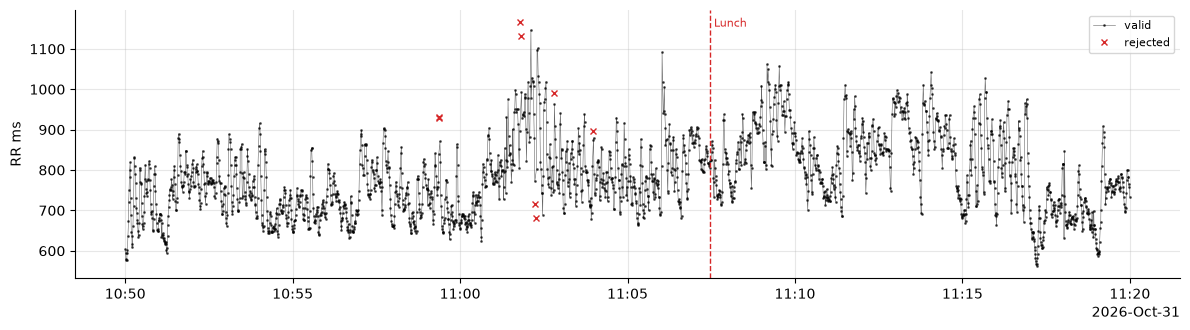

In [3]:
NN = beat_table(S, S.get("rr"))
print(f"{len(NN):,} intervals · {NN['valid'].mean():.1%} valid · {NN['pair'].mean():.1%} valid pairs")

fig, ax = plt.subplots(figsize=(12, 3.4))
ax.plot(NN.loc[NN["valid"], "t"], NN.loc[NN["valid"], "ms"], ".-", ms=2, lw=0.4, color="k", alpha=0.6, label="valid")
ax.plot(NN.loc[~NN["valid"], "t"], NN.loc[~NN["valid"], "ms"].clip(250, 1600), "x", ms=4, color="C3", label="rejected")
ax.set_ylabel("RR ms"); ax.legend(fontsize=8)
decorate(ax, S, labels=True); time_axis(ax); plt.tight_layout(); plt.show()

## Metrics

| group | metric | meaning |
|---|---|---|
| time | mean RR, mean / min / max HR | min/max use the 1st/99th percentile |
| | **SDNN** | overall variability (depends on the window length) |
| | **RMSSD**, SDSD, **pNN50** | beat-to-beat variability, vagal (parasympathetic) |
| | HRV triangular index | beats / height of the 1/128 s histogram |
| Poincaré | **SD1**, **SD2**, SD2/SD1 | short- and long-term variability (SD1 = RMSSD / √2) |
| frequency | **VLF** 0.0033–0.04, **LF** 0.04–0.15, **HF** 0.15–0.4 Hz | power in ms², LF/HF, normalised units |
| | HF peak | ≈ breathing rate when it is within 9–24 /min |

Frequency domain: valid intervals → 4 Hz tachogram → linear detrend → Welch. The standard window is **5 minutes at rest**; values for the whole log are means of the 5-minute windows. VLF needs longer windows; in 5 minutes it is indicative only.

In [4]:
W5 = hrv_windows(S, NN)
FREQ = ["VLF ms²", "LF ms²", "HF ms²", "total ms²", "LF/HF", "LF nu", "HF nu", "HF peak /min"]
whole = {**hrv_time(NN), **{f"{c} (5-min mean)": W5[c].mean() for c in FREQ}}
pd.Series(whole).round(2).to_frame("whole log")

,whole log
beats,2309.00
artefact %,0.35
mean RR ms,778.86
mean HR,77.04
min HR,59.35
max HR,99.50
SDNN ms,92.74
RMSSD ms,35.13
SDSD ms,35.13
pNN50 %,9.85


## Before and after lunch

The *Lunch* marker splits the log. Heart rate typically rises and vagal HRV drops after a meal, but here the sensors were worn during an ordinary day, so movement and posture change too; treat the difference as an example, not a finding.

In [5]:
mk = S.markers["elapsed_s"].iloc[0]
acc = S.get("acc", "H10")
acc["mag"] = np.sqrt(acc["x_mg"] ** 2 + acc["y_mg"] ** 2 + acc["z_mg"] ** 2.0)

def segment(a, b):
    w = NN[(NN["elapsed_s"] >= a) & (NN["elapsed_s"] < b)]
    m = acc["mag"][(acc["elapsed_s"] >= a) & (acc["elapsed_s"] < b)]
    return {"from": f"{S.to_local(a):%H:%M}", "to": f"{S.to_local(b):%H:%M}",
            "chest ENMO mg": np.clip(m - 1000, 0, None).mean(), **hrv_time(w), **hrv_freq(w)}

pd.DataFrame({"before lunch": segment(0, mk), "after lunch": segment(mk, S.end_s)}).map(
    lambda v: round(v, 1) if isinstance(v, float) else v)

,before lunch,after lunch
from,10:50,11:07
to,11:07,11:20
chest ENMO mg,13.2,5.8
beats,1376,933
artefact %,0.6,0.0
mean RR ms,759.9,806.7
mean HR,79.0,74.4
min HR,59.6,59.3
max HR,97.0,101.3
SDNN ms,80.9,101.6


## 5-minute trend

Bottom panel: chest movement (ENMO: acceleration magnitude minus 1 g). HRV is easiest to interpret in quiet windows.

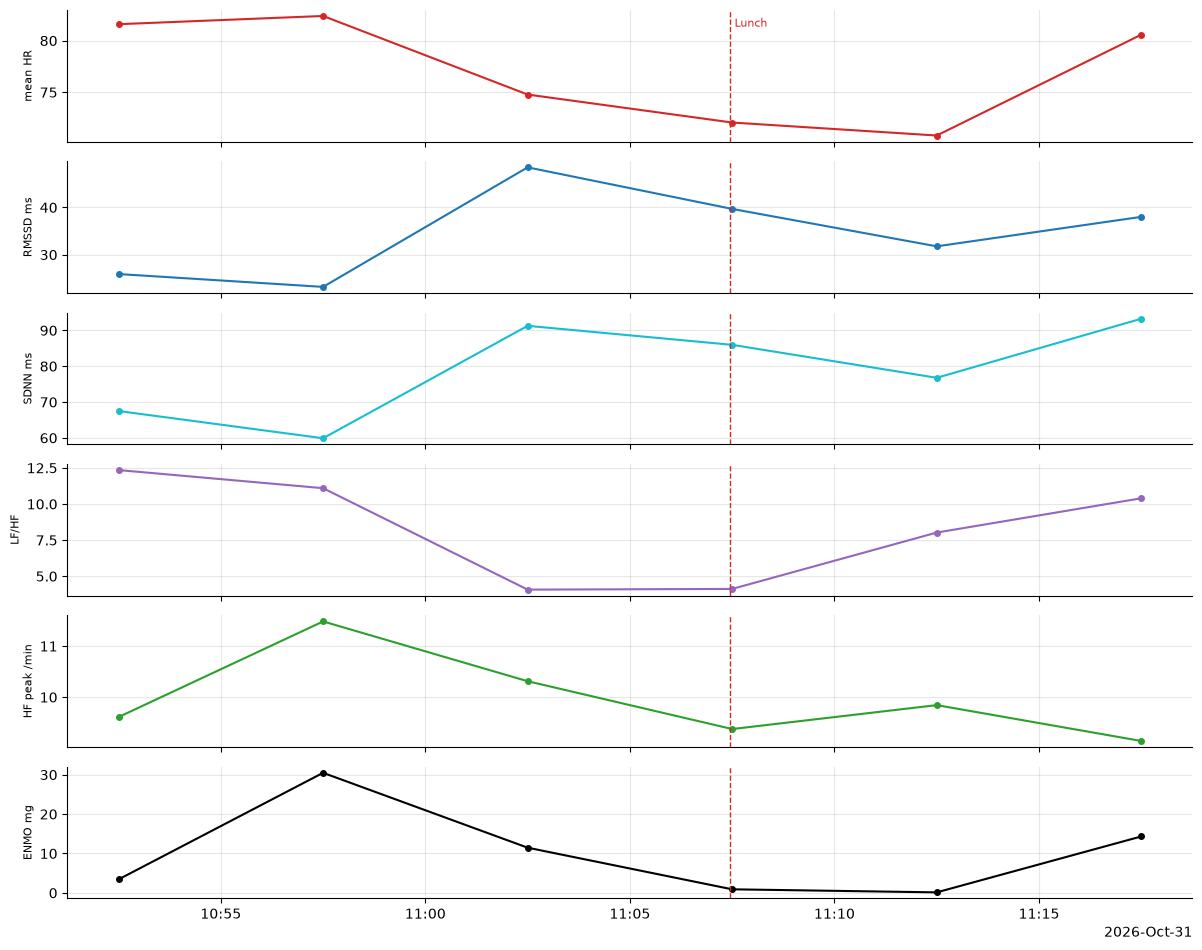

,start_s,beats,artefact %,mean RR ms,mean HR,min HR,max HR,SDNN ms,RMSSD ms,SDSD ms,pNN50 %,HRV tri index,SD1 ms,SD2 ms,SD2/SD1,VLF ms²,LF ms²,HF ms²,total ms²,LF/HF,LF nu,HF nu,HF peak /min,ENMO mg
t,,,,,,,,,,,,,,,,,,,,,,,,
2026-10-31 10:52:30,0.0,408,0.0,735.4,81.6,67.6,101.0,67.5,25.9,25.9,4.7,17.7,18.3,92.9,5.1,1232.1,1460.3,118.2,2810.6,12.4,92.5,7.5,9.6,3.4
2026-10-31 10:57:30,300.0,411,0.5,728.3,82.4,67.5,93.5,59.9,23.2,23.2,4.5,14.1,16.4,80.3,4.9,2890.6,1307.6,117.8,4316.0,11.1,91.7,8.3,11.5,30.5
2026-10-31 11:02:30,600.0,373,1.6,802.3,74.8,58.2,91.5,91.3,48.5,48.5,18.8,16.7,34.3,128.0,3.7,4620.2,4367.1,1072.1,10059.4,4.1,80.3,19.7,10.3,11.5
2026-10-31 11:07:30,900.0,360,0.0,832.5,72.1,58.2,88.2,86.0,39.7,39.7,14.9,16.4,28.1,121.9,4.3,2277.1,1344.6,326.2,3947.8,4.1,80.5,19.5,9.4,0.9
2026-10-31 11:12:30,1200.0,355,0.0,847.3,70.8,59.6,87.4,76.8,31.8,31.8,7.1,14.8,22.5,109.8,4.9,1470.4,1883.6,234.7,3588.7,8.0,88.9,11.1,9.8,0.1
2026-10-31 11:17:30,1500.0,402,0.0,744.6,80.6,61.3,103.3,93.3,38.0,38.1,10.9,16.1,26.9,129.0,4.8,4965.7,3016.8,290.1,8272.6,10.4,91.2,8.8,9.1,14.3


In [6]:
enmo = np.clip(acc["mag"] - 1000, 0, None).groupby(np.floor(acc["elapsed_s"] / 300) * 300).mean()
W5["ENMO mg"] = W5["start_s"].map(enmo)
cols = [("mean HR", "C3"), ("RMSSD ms", "C0"), ("SDNN ms", "C9"), ("LF/HF", "C4"), ("HF peak /min", "C2"), ("ENMO mg", "k")]
fig, axes = plt.subplots(len(cols), 1, figsize=(12, 1.6 * len(cols)), sharex=True)
for ax, (c, color) in zip(axes, cols):
    ax.plot(W5["t"], W5[c], "o-", ms=4, color=color)
    ax.set_ylabel(c, fontsize=8)
    decorate(ax, S, labels=ax is axes[0])
time_axis(axes[-1]); plt.tight_layout(); plt.show()
W5.set_index("t").round(1)

## Poincaré plot and spectrum

The whole log as a density, and the 5-minute window with the least chest movement and < 5 % artefacts, with its SD1/SD2 ellipse and RR spectrum.

quietest window 11:10–11:15


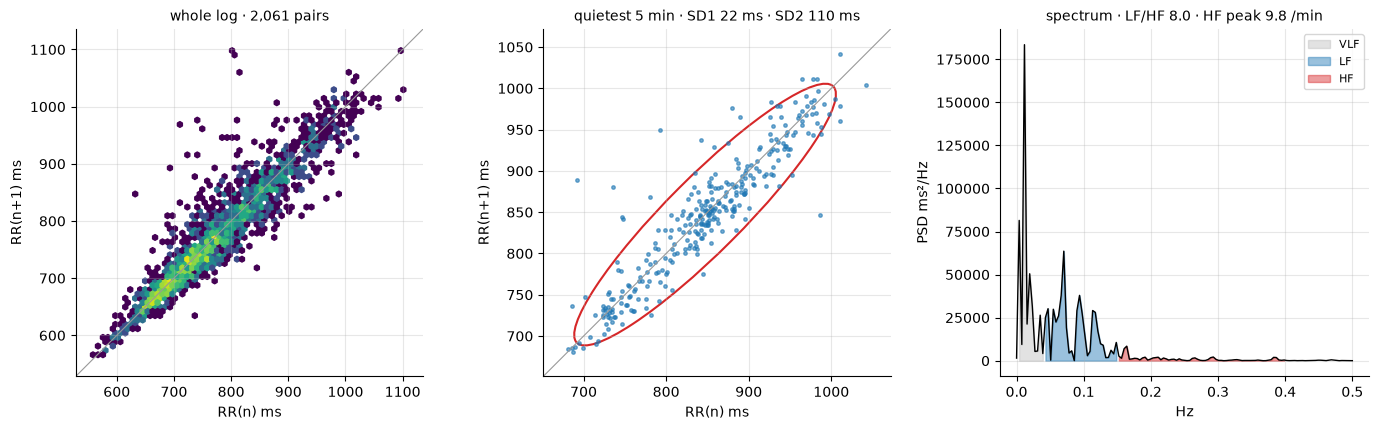

In [7]:
from matplotlib.patches import Ellipse

cand = W5[(W5["artefact %"] < 5) & W5["LF ms²"].notna()]
a = cand.loc[cand["ENMO mg"].idxmin(), "start_s"]
w = NN[(NN["elapsed_s"] >= a) & (NN["elapsed_s"] < a + 300)]
res, f, p = hrv_freq(w, return_psd=True)
tm = hrv_time(w)
print(f"quietest window {S.to_local(a):%H:%M}–{S.to_local(a + 300):%H:%M}")

def pairs(df):
    ms, ok = df["ms"].to_numpy(), df["pair"].to_numpy()
    return ms[:-1][ok[1:]], ms[1:][ok[1:]]

fig, axes = plt.subplots(1, 3, figsize=(14, 4.4))
x, y = pairs(NN)
lo, hi = np.percentile(np.r_[x, y], [0.1, 99.9]) + [-40, 40]
axes[0].hexbin(x, y, gridsize=70, bins="log", cmap="viridis", extent=(lo, hi, lo, hi), mincnt=1)
axes[0].set_xlim(lo, hi); axes[0].set_ylim(lo, hi)
axes[0].set_title(f"whole log · {len(x):,} pairs", fontsize=10)
xw, yw = pairs(w)
axes[1].plot(xw, yw, ".", ms=5, alpha=0.6)
c = np.mean(np.r_[xw, yw])
axes[1].add_patch(Ellipse((c, c), 4 * tm["SD2 ms"], 4 * tm["SD1 ms"], angle=45, fill=False, color="C3", lw=1.5))
axes[1].set_title(f"quietest 5 min · SD1 {tm['SD1 ms']:.0f} ms · SD2 {tm['SD2 ms']:.0f} ms", fontsize=10)
lo2, hi2 = min(xw.min(), yw.min()) - 30, max(xw.max(), yw.max()) + 30
axes[1].set_xlim(lo2, hi2); axes[1].set_ylim(lo2, hi2)
for ax in axes[:2]:
    ax.plot([0, 3000], [0, 3000], color="0.6", lw=0.8, scalex=False, scaley=False)
    ax.set_aspect("equal"); ax.set_xlabel("RR(n) ms"); ax.set_ylabel("RR(n+1) ms")
m = f <= 0.5
axes[2].plot(f[m], p[m], color="k", lw=1)
for f0, f1, name, color in [(0.0033, 0.04, "VLF", "0.75"), (0.04, 0.15, "LF", "C0"), (0.15, 0.4, "HF", "C3")]:
    b = (f >= f0) & (f <= f1)
    axes[2].fill_between(f[b], p[b], color=color, alpha=0.45, label=name)
axes[2].set_xlabel("Hz"); axes[2].set_ylabel("PSD ms²/Hz"); axes[2].legend(fontsize=8)
axes[2].set_title(f"spectrum · LF/HF {res['LF/HF']:.1f} · HF peak {res['HF peak /min']:.1f} /min", fontsize=10)
plt.tight_layout(); plt.show()

## RR (ECG) vs. PPI (optical)

The Verity Sense computes PP intervals from its PPG. PPI is very sensitive to movement (Polar recommends it at complete rest only) and the first ~25 s after start contain none. Same cleaning as RR, plus `blocker == 0` and skin contact.

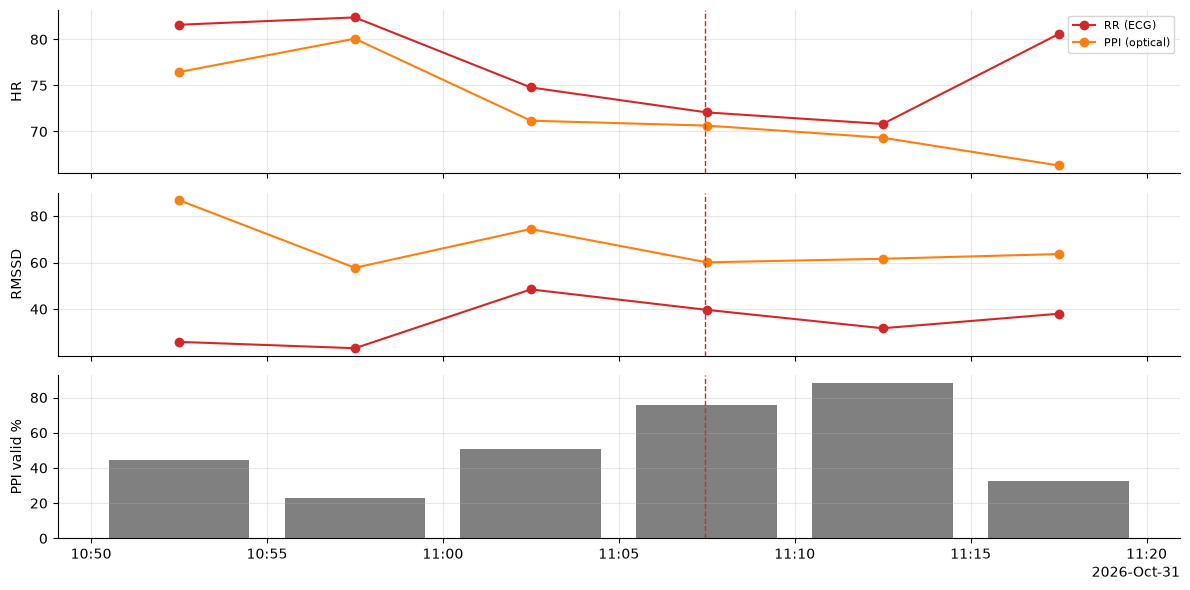

,HR (RR),HR (PPI),RMSSD (RR),RMSSD (PPI),PPI valid %
t,,,,,
2026-10-31 10:52:30,81.6,76.5,25.9,86.9,44.6
2026-10-31 10:57:30,82.4,80.1,23.2,57.8,23.2
2026-10-31 11:02:30,74.8,71.2,48.5,74.5,50.6
2026-10-31 11:07:30,72.1,70.6,39.7,60.1,75.7
2026-10-31 11:12:30,70.8,69.3,31.8,61.7,88.1
2026-10-31 11:17:30,80.6,66.3,38.0,63.7,32.7


In [8]:
PP = ppi_table(S, S.get("ppi"))
W5_pp = hrv_windows(S, PP)
cmp = pd.DataFrame({"t": W5["t"], "HR (RR)": W5["mean HR"], "HR (PPI)": W5_pp["mean HR"],
                    "RMSSD (RR)": W5["RMSSD ms"], "RMSSD (PPI)": W5_pp["RMSSD ms"],
                    "PPI valid %": 100 - W5_pp["artefact %"]})
fig, axes = plt.subplots(3, 1, figsize=(12, 6), sharex=True)
for ax, (a_, b_) in zip(axes[:2], [("HR (RR)", "HR (PPI)"), ("RMSSD (RR)", "RMSSD (PPI)")]):
    ax.plot(cmp["t"], cmp[a_], "o-", color="C3", label="RR (ECG)")
    ax.plot(cmp["t"], cmp[b_], "o-", color="C1", label="PPI (optical)")
    ax.set_ylabel(a_.split()[0])
axes[0].legend(fontsize=8)
axes[2].bar(cmp["t"], cmp["PPI valid %"], width=pd.Timedelta(minutes=4), color="0.5"); axes[2].set_ylabel("PPI valid %")
for ax in axes:
    decorate(ax, S)
time_axis(axes[-1]); plt.tight_layout(); plt.show()
cmp.set_index("t").round(1)

Mean heart rate agrees within a few beats per minute, but RMSSD from PPI comes out clearly higher: the optical sensor's beat detection adds timing jitter of some tens of milliseconds, and RMSSD, built from successive differences, picks it up directly. For HRV, use the ECG-based RR intervals; PPI is fine for heart rate and for HRV only at complete rest.